In [ ]:
!pip install geopy

In [61]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 2.8 MB/s eta 0:00:18
   - -------------------------------------- 1.8/48.9 MB 3.9 MB/s eta 0:00:13
   -- ------------------------------------- 3.7/48.9 MB 5.1 MB/s eta 0:00:09
   --- ------------------------------------ 4.7/48.9 MB 4.8 MB/s eta 0:00:10
   ---- ----------------------------------- 5.5/48.9 MB 4.7 MB/s eta 0:00:10
   ---- ----------------------------------- 6.0/48.9 MB 4.6 MB/s eta 0:00:10
   ----- ---------------------------------- 7.1/48.9 MB 4.4 MB/s eta 0:00:10
   ------ --------------------------------- 7.6/48.9 MB 4.3 MB/s eta 0:00:10
   ------ --------------------------------- 7.9/48.9 MB 4.2 MB/s eta 0:00:10
   ------- ----------------


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import seaborn as sns 
import numpy as np
import matplotlib.pyplot as plt

from geopy.distance import geodesic

from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import  OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import StackingRegressor

from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor


from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

import joblib


# Reading of Tables 

In [3]:
orders_df = pd.read_csv('Data_Cleaning/olist_orders_cols_cleaned.csv')

In [5]:
orders_items_df = pd.read_csv('Data_Cleaning/olist_order_items_cols_cleaned.csv')

In [6]:
geo_df = pd.read_csv('Data_Cleaning/olist_geolocation_cols_cleaned.csv')

In [9]:
seller_df = pd.read_csv('Data_Cleaning/olist_sellers_col_cleaned.csv')

In [11]:
customer_df = pd.read_csv('Data_Cleaning/olist_customers_cols_cleaned.csv')

In [13]:
category_trans_df = pd.read_csv('Data_Cleaning/product_category_name_translation.csv')

In [15]:
products_df =  pd.read_csv('Data_Cleaning/olist_products_cols_cleaned.csv')

# Table Merging

In [17]:
geo_df = (geo_df.groupby("geolocation_zip_code_prefix")
          [["geolocation_lat", "geolocation_lng"]].mean().reset_index())

geo_cust = geo_df.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                               "geolocation_lat": "cust_lat",
                               "geolocation_lng": "cust_lng"})
geo_sell = geo_df.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix",
                               "geolocation_lat": "sell_lat",
                               "geolocation_lng": "sell_lng"})

In [126]:
df = (orders_df
      .merge(customer_df, on="customer_id", how="left")
      .merge(reviews_df, on="order_id", how="left")
      .merge(orders_items_df, on="order_id", how="left")
      .merge(products_df, on="product_id", how="left")
      .merge(seller_df, on="seller_id", how="left")
      .merge(geo_cust, on="customer_zip_code_prefix", how="left")
      .merge(geo_sell, on="seller_zip_code_prefix", how="left"))

In [128]:
df.columns

Index(['order_id', 'customer_id', 'order_purchase_timestamp',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'customer_zip_code_prefix', 'state_name', 'review_id', 'review_score',
       'review_comment_title', 'review_comment_title_english',
       'review_comment_message', 'review_comment_message_english',
       'review_creation_date', 'review_answer_timestamp', 'Unnamed: 0',
       'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value',
       'product_category_name', 'product_weight_g', 'product_length_cm',
       'product_height_cm', 'product_width_cm', 'seller_state_name',
       'seller_zip_code_prefix', 'cust_lat', 'cust_lng', 'sell_lat',
       'sell_lng'],
      dtype='object')

In [136]:
print(reviews_df["order_id"].duplicated().sum())

0


In [134]:
reviews_df = reviews_df.drop_duplicates(subset="order_id", keep="first")

In [138]:
order_df = (df.groupby("order_id").agg(
    customer_id=("customer_id", "first"),
    number_of_items=("order_item_id", "count"),
    price=("price", "sum"),
    freight=("freight_value", "sum"),
    overal_weight_g=("product_weight_g", "sum"),
    length_cm=("product_length_cm", "max"),
    height_cm=("product_height_cm", "max"),
    width_cm=("product_width_cm", "max"),
    product_id=("product_id", "first"),
    product_category_name=("product_category_name", "first"),
    seller_id=("seller_id", "first"),
    customer_state=("state_name", "first"),
    seller_state=("seller_state_name", "first"),
    customer_zip_code_prefix=("customer_zip_code_prefix", "first"),
    seller_zip_code_prefix=("seller_zip_code_prefix", "first"),
    cust_lat=("cust_lat", "first"),
    cust_lng=("cust_lng", "first"),
    sell_lat=("sell_lat", "first"),
    sell_lng=("sell_lng", "first"),
    purchase_ts=("order_purchase_timestamp", "first"),
    carrier_delivery_date=("order_delivered_carrier_date", "first"),
    customer_delivery_date=("order_delivered_customer_date", "first"),
    review_score=("review_score", "first")
).reset_index())

print(order_df.shape)

(96449, 24)


In [140]:
order_df.head(30)

,order_id,customer_id,number_of_items,price,freight,overal_weight_g,length_cm,height_cm,width_cm,product_id,product_category_name,seller_id,customer_state,seller_state,customer_zip_code_prefix,seller_zip_code_prefix,cust_lat,cust_lng,sell_lat,sell_lng,purchase_ts,carrier_delivery_date,customer_delivery_date,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,1,58.90,13.29,650.0,28.0,9.0,14.0,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,48436dade18ac8b2bce089ec2a041202,Rio de Janeiro,Sao Paulo,28013,27277,-21.763186,-41.310265,-22.497188,-44.127324,2017-09-13,2017-09-19,2017-09-20,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,1,239.90,19.93,30000.0,50.0,30.0,40.0,e5f2d52b802189ee658865ca93d83a8f,pet_shop,dd7ddc04e1b6c2c614352b383efe2d36,Sao Paulo,Sao Paulo,15775,3471,-20.222506,-50.898951,-23.565754,-46.519097,2017-04-26,2017-05-04,2017-05-12,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,1,199.00,17.87,3050.0,33.0,13.0,33.0,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,5b51032eddd242adc84c38acab88f23d,Minas Gerais,Minas Gerais,35661,37564,-19.869998,-44.593059,-22.262802,-46.170735,2018-01-14,2018-01-16,2018-01-22,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,1,12.99,12.79,200.0,16.0,10.0,15.0,7634da152a4610f1595efa32f14722fc,perfumaria,9d7a1d34a5052409006425275ba1c2b4,Sao Paulo,Sao Paulo,12952,14403,-23.105968,-46.590277,-20.553651,-47.387145,2018-08-08,2018-08-10,2018-08-14,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,1,199.90,18.14,3750.0,35.0,40.0,30.0,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,df560393f3a51e74553ab94004ba5c87,Sao Paulo,Parana,13226,87900,-23.243402,-46.827614,-22.929583,-53.135750,2017-02-04,2017-02-16,2017-03-01,5.0
5,00048cc3ae777c65dbb7d2a0634bc1ea,816cbea969fe5b689b39cfc97a506742,1,21.90,12.69,450.0,24.0,8.0,15.0,ef92defde845ab8450f9d70c526ef70f,utilidades_domesticas,6426d21aca402a131fc0a5d0960a3c90,Minas Gerais,Sao Paulo,38017,14091,-19.739990,-47.924643,-21.189922,-47.787945,2017-05-15,2017-05-17,2017-05-22,4.0
6,00054e8431b9d7675808bcb819fb4a32,32e2e6ab09e778d99bf2e0ecd4898718,1,19.90,11.85,200.0,27.0,5.0,20.0,8d4f2bb7e93e6710a28f34fa83ee7d28,telefonia,7040e82f899a04d1b434b795a43b4617,Sao Paulo,Sao Paulo,16700,1026,-21.250677,-50.646525,-23.539639,-46.632154,2017-12-10,2017-12-12,2017-12-18,4.0
7,000576fe39319847cbb9d288c5617fa6,9ed5e522dd9dd85b4af4a077526d8117,1,810.00,70.75,13805.0,35.0,75.0,45.0,557d850972a7d6f792fd18ae1400d9b6,ferramentas_jardim,5996cddab893a4652a15592fb58ab8db,Sao Paulo,Sao Paulo,11702,19010,-24.014083,-46.437837,-22.123027,-51.386427,2018-07-04,2018-07-05,2018-07-09,5.0
8,0005a1a1728c9d785b8e2b08b904576c,16150771dfd4776261284213b89c304e,1,145.95,11.65,2000.0,30.0,12.0,16.0,310ae3c140ff94b03219ad0adc3c778f,beleza_saude,a416b6a846a11724393025641d4edd5e,Sao Paulo,Sao Paulo,11075,3702,-23.954263,-46.337663,-23.515892,-46.547523,2018-03-19,2018-03-28,2018-03-29,1.0
9,0005f50442cb953dcd1d21e1fb923495,351d3cb2cee3c7fd0af6616c82df21d3,1,53.99,11.40,850.0,29.0,3.0,21.0,4535b0e1091c278dfd193e5a1d63b39f,livros_tecnicos,ba143b05f0110f0dc71ad71b4466ce92,Sao Paulo,Sao Paulo,6636,2274,-23.556562,-46.899179,-23.466989,-46.587803,2018-07-02,2018-07-03,2018-07-04,4.0


In [142]:
pd.set_option('display.max_columns', None)
order_df

,order_id,customer_id,number_of_items,price,freight,overal_weight_g,length_cm,height_cm,width_cm,product_id,product_category_name,seller_id,customer_state,seller_state,customer_zip_code_prefix,seller_zip_code_prefix,cust_lat,cust_lng,sell_lat,sell_lng,purchase_ts,carrier_delivery_date,customer_delivery_date,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,1,58.90,13.29,650.0,28.0,9.0,14.0,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,48436dade18ac8b2bce089ec2a041202,Rio de Janeiro,Sao Paulo,28013,27277,-21.763186,-41.310265,-22.497188,-44.127324,2017-09-13,2017-09-19,2017-09-20,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,1,239.90,19.93,30000.0,50.0,30.0,40.0,e5f2d52b802189ee658865ca93d83a8f,pet_shop,dd7ddc04e1b6c2c614352b383efe2d36,Sao Paulo,Sao Paulo,15775,3471,-20.222506,-50.898951,-23.565754,-46.519097,2017-04-26,2017-05-04,2017-05-12,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,1,199.00,17.87,3050.0,33.0,13.0,33.0,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,5b51032eddd242adc84c38acab88f23d,Minas Gerais,Minas Gerais,35661,37564,-19.869998,-44.593059,-22.262802,-46.170735,2018-01-14,2018-01-16,2018-01-22,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,1,12.99,12.79,200.0,16.0,10.0,15.0,7634da152a4610f1595efa32f14722fc,perfumaria,9d7a1d34a5052409006425275ba1c2b4,Sao Paulo,Sao Paulo,12952,14403,-23.105968,-46.590277,-20.553651,-47.387145,2018-08-08,2018-08-10,2018-08-14,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,1,199.90,18.14,3750.0,35.0,40.0,30.0,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,df560393f3a51e74553ab94004ba5c87,Sao Paulo,Parana,13226,87900,-23.243402,-46.827614,-22.929583,-53.135750,2017-02-04,2017-02-16,2017-03-01,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96444,fffc94f6ce00a00581880bf54a75a037,b51593916b4b8e0d6f66f2ae24f2673d,1,299.99,43.41,10150.0,89.0,15.0,40.0,4aa6014eceb682077f9dc4bffebc05b0,utilidades_domesticas,b8bc237ba3788b23da09c0f1f3a3288c,Maranhao,Santa Catarina,65077,88303,-2.499937,-44.295904,-26.912506,-48.674090,2018-04-23,2018-04-25,2018-05-10,5.0
96445,fffcd46ef2263f404302a634eb57f7eb,84c5d4fbaf120aae381fad077416eaa0,1,350.00,36.53,8950.0,45.0,26.0,38.0,32e07fd915822b0765e448c4dd74c828,informatica_acessorios,f3c38ab652836d21de61fb8314b69182,Parana,Sao Paulo,81690,1206,-25.582933,-49.313298,-23.535839,-46.642848,2018-07-14,2018-07-17,2018-07-23,5.0
96446,fffce4705a9662cd70adb13d4a31832d,29309aa813182aaddc9b259e31b870e6,1,99.90,16.95,967.0,21.0,24.0,19.0,72a30483855e2eafc67aee5dc2560482,esporte_lazer,c3cfdc648177fdbbbb35635a37472c53,Sao Paulo,Parana,4039,80610,-23.597320,-46.643843,-25.469563,-49.288176,2017-10-23,2017-10-26,2017-10-28,5.0
96447,fffe18544ffabc95dfada21779c9644f,b5e6afd5a41800fdf401e0272ca74655,1,55.99,8.72,100.0,20.0,20.0,20.0,9c422a519119dcad7575db5af1ba540e,informatica_acessorios,2b3e4a2a3ea8e01938cabda2a3e5cc79,Sao Paulo,Sao Paulo,13289,4733,-23.039798,-46.979488,-23.637701,-46.695548,2017-08-14,2017-08-15,2017-08-16,5.0


In [144]:
brazil = (order_df["cust_lat"].between(-33.75, 5.27)& order_df["cust_lng"].between(-73.99, -34.79))

In [146]:
order_df[~brazil]

,order_id,customer_id,number_of_items,price,freight,overal_weight_g,length_cm,height_cm,width_cm,product_id,product_category_name,seller_id,customer_state,seller_state,customer_zip_code_prefix,seller_zip_code_prefix,cust_lat,cust_lng,sell_lat,sell_lng,purchase_ts,carrier_delivery_date,customer_delivery_date,review_score
215,009fa9bd0d92710e840793bfefa80867,ed19fa6ce948d52be769926c2baaa17c,1,84.99,15.34,550.0,21.0,12.0,20.0,617186c3d97ea56c9c683a8a3974e8c1,perfumaria,cc419e0650a3c5ba77189a1882b7556a,Minas Gerais,Sao Paulo,38710,9015,NaN,NaN,-23.659354,-46.523359,2017-06-14,2017-06-19,2017-07-08,4.0
686,01d3d4cb8c553d507dfd26fbd8b41e95,814dfd64a142fe2564faef3932b676b9,1,114.94,34.16,7400.0,54.0,53.0,20.0,33e77eecc23c25a65d10f627e5053617,moveis_escritorio,7c67e1448b00f6e969d365cea6b010ab,Rio de Janeiro,Sao Paulo,28655,8577,NaN,NaN,-23.486138,-46.367107,2017-10-29,2017-11-10,2017-11-16,3.0
892,02623e799dcc1e41066ddfe4af591f24,5ffea9b2ecf7eb23b4db0b1c4f76765d,1,52.99,15.12,150.0,23.0,7.0,17.0,ffd34459c21034d1da6df9800de0d7a3,beleza_saude,11bfa66332777660bd0640ee84d47006,Federal District,Sao Paulo,73401,14085,NaN,NaN,-21.166047,-47.797949,2017-12-06,2017-12-06,2017-12-23,4.0
1000,02acaa2a6f24e9c4e0bec7141b65f29b,198f8a1c41eaeb274fc8b25993320f18,1,29.90,14.10,200.0,25.0,5.0,15.0,06c6e01186af8b98ee1fc9e01f9471e9,informatica_acessorios,fc906263ca5083d09dce42fe02247800,Federal District,Minas Gerais,72268,31030,NaN,NaN,-19.905869,-43.923902,2017-09-07,2017-09-08,2017-09-13,2.0
1570,041cba819a99569f87996b65b73ea82e,98f405f18fec61e1a61037c344213e26,1,23.99,14.16,100.0,20.0,15.0,15.0,154e7e31ebfa092203795c972e5804a6,beleza_saude,cc419e0650a3c5ba77189a1882b7556a,Federal District,Sao Paulo,72536,9015,NaN,NaN,-23.659354,-46.523359,2018-03-18,2018-03-19,2018-03-22,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93876,f94344586ac6663aabd08cbb1381e347,8ff02d450ba93882e5d0277f2fdc8727,1,38.90,18.23,375.0,17.0,4.0,14.0,d759fd6b0285e54cf1bc5041e2a286bd,automotivo,8b28d096634035667e8263d57ba3368c,Goias,Sao Paulo,72821,12243,NaN,NaN,-23.201636,-45.897259,2018-04-20,2018-04-25,2018-05-02,5.0
94517,fae78da81b7ad4a5389732f61e0264ef,90b17430567733d3e005cc92466c213a,4,75.60,60.40,1200.0,40.0,4.0,30.0,25bf7c5e5f9d008845212122805014e5,cama_mesa_banho,d2374cbcbb3ca4ab1086534108cc3ab7,Federal District,Sao Paulo,70701,14940,NaN,NaN,-21.757225,-48.829541,2017-06-06,2017-06-08,2017-06-19,4.0
95473,fd5c73fb6edc88486582bf0a0bb989aa,c348e5bd22ca24a447a221536c71d8b3,1,199.99,13.84,400.0,20.0,8.0,50.0,5861173d9af66445f070078cfc29a597,beleza_saude,59fb871bf6f4522a87ba567b42dafecf,Sao Paulo,Sao Paulo,12770,3655,NaN,NaN,-23.525436,-46.513769,2018-04-09,2018-04-11,2018-04-17,5.0
95897,fe784ed3dfc728fd4de44fa9918fe1eb,534ae76adc5da4b4f9c7b505a756d59d,1,39.90,18.08,1075.0,21.0,19.0,19.0,9ac1378f05cd222b3fb34a3cccc626c7,beleza_saude,f46490624488d3ff7ce78613913a7711,Federal District,Sao Paulo,71574,7194,NaN,NaN,-23.442999,-46.506324,2018-07-31,2018-08-02,2018-08-06,5.0


In [148]:
order_df = order_df[brazil].copy()

In [152]:
order_df["purchase_ts"] = pd.to_datetime(order_df["purchase_ts"])
order_df["customer_delivery_date"] = pd.to_datetime(order_df["customer_delivery_date"])
order_df["carrier_delivery_date"] = pd.to_datetime(order_df["carrier_delivery_date"])

# Feature Enginnering 

### Creating our target label: 

In [156]:
order_df['time_to_deliver'] = (order_df['customer_delivery_date'] - order_df['purchase_ts']).dt.days

In [158]:
order_df['time_to_deliver']

0         7
1        16
2         8
3         6
4        25
         ..
96444    17
96445     9
96446     5
96447     2
96448     5
Name: time_to_deliver, Length: 96176, dtype: int64

### Creating the distance: 

In [160]:
order_df.isnull().mean() * 100

order_id                    0.000000
customer_id                 0.000000
number_of_items             0.000000
price                       0.000000
freight                     0.000000
overal_weight_g             0.000000
length_cm                   0.022875
height_cm                   0.022875
width_cm                    0.022875
product_id                  0.000000
product_category_name       1.386001
seller_id                   0.000000
customer_state              0.000000
seller_state                0.000000
customer_zip_code_prefix    0.000000
seller_zip_code_prefix      0.000000
cust_lat                    0.000000
cust_lng                    0.000000
sell_lat                    0.220429
sell_lng                    0.220429
purchase_ts                 0.000000
carrier_delivery_date       0.000000
customer_delivery_date      0.000000
review_score                0.670645
time_to_deliver             0.000000
dtype: float64

In [162]:
order_df = order_df.dropna(subset=[ 'cust_lat' ])

In [164]:
order_df = order_df.dropna(subset=[ 'sell_lat' ])

In [166]:
order_df.isnull().mean() * 100

order_id                    0.000000
customer_id                 0.000000
number_of_items             0.000000
price                       0.000000
freight                     0.000000
overal_weight_g             0.000000
length_cm                   0.022925
height_cm                   0.022925
width_cm                    0.022925
product_id                  0.000000
product_category_name       1.388021
seller_id                   0.000000
customer_state              0.000000
seller_state                0.000000
customer_zip_code_prefix    0.000000
seller_zip_code_prefix      0.000000
cust_lat                    0.000000
cust_lng                    0.000000
sell_lat                    0.000000
sell_lng                    0.000000
purchase_ts                 0.000000
carrier_delivery_date       0.000000
customer_delivery_date      0.000000
review_score                0.672127
time_to_deliver             0.000000
dtype: float64

In [168]:
order_df['distance_km'] = order_df.apply(
    lambda row: geodesic(
        (row['sell_lat'], row['sell_lng']),
        (row['cust_lat'], row['cust_lng'])
    ).km,
    axis =1
)

In [169]:
order_df['distance_km']

0         301.773645
1         584.635144
2         311.548958
3         294.373438
4         647.195585
            ...     
96444    2741.602463
96445     352.972885
96446     338.804900
96447      72.303756
96448     134.480370
Name: distance_km, Length: 95964, dtype: float64

### Creating dates columns

In [172]:
order_df['purchase_month'] = order_df['purchase_ts'].dt.month

In [174]:
order_df['purchase_day'] = order_df['purchase_ts'].dt.day

# EDA

In [29]:
order_df.describe()

,number_of_items,price,freight,overal_weight_g,length_cm,height_cm,width_cm,customer_zip_code_prefix,seller_zip_code_prefix,cust_lat,cust_lng,sell_lat,sell_lng,purchase_ts,carrier_delivery_date,customer_delivery_date,time_to_deliver,distance_km,purchase_month,purchase_day
count,95964.000000,95964.000000,95964.000000,95964.000000,95942.000000,95942.000000,95942.000000,95964.000000,95964.000000,95964.000000,95964.000000,95964.000000,95964.000000,95964,95964,95964,95964.000000,95964.000000,95964.000000,95964.000000
mean,1.142126,137.078056,22.775977,2384.443562,30.201017,16.560630,23.098487,35115.799300,24661.074205,-21.203430,-46.189872,-22.795842,-47.225232,2018-01-01 09:22:35.458296832,2018-01-04 14:30:30.386394880,2018-01-13 21:02:55.115668224,12.486339,599.334129,6.030157,15.518403
min,1.000000,0.850000,0.000000,0.000000,7.000000,2.000000,6.000000,1003.000000,1001.000000,-33.689890,-72.668821,-32.075303,-63.893789,2016-09-15 00:00:00,2016-10-08 00:00:00,2016-10-11 00:00:00,0.000000,0.000000,1.000000,1.000000
25%,1.000000,45.900000,13.830000,300.000000,18.000000,8.000000,15.000000,11320.000000,6440.000000,-23.590087,-48.117725,-23.612499,-48.807283,2017-09-14 00:00:00,2017-09-18 00:00:00,2017-09-25 00:00:00,7.000000,185.819528,3.000000,8.000000
50%,1.000000,86.000000,17.160000,750.000000,25.000000,13.000000,20.000000,24360.000000,13568.000000,-22.924376,-46.632105,-23.424361,-46.748090,2018-01-20 00:00:00,2018-01-24 00:00:00,2018-02-02 00:00:00,10.000000,433.439626,6.000000,16.000000
75%,1.000000,149.900000,24.000000,2050.000000,38.000000,20.000000,30.000000,58640.000000,29156.000000,-20.139634,-43.629352,-21.757225,-46.519097,2018-05-05 00:00:00,2018-05-08 00:00:00,2018-05-15 00:00:00,16.000000,797.195279,8.000000,23.000000
max,21.000000,13440.000000,1794.960000,184400.000000,105.000000,105.000000,118.000000,99980.000000,99730.000000,3.843299,-34.799347,-2.503158,-34.855831,2018-08-29 00:00:00,2018-09-11 00:00:00,2018-10-17 00:00:00,210.000000,3918.440625,12.000000,31.000000
std,0.538916,209.312396,21.581289,4768.062664,16.158954,13.351264,11.743458,29826.513552,27739.156925,5.590564,4.050834,2.755162,2.350256,NaN,NaN,NaN,9.548967,590.478053,3.228561,8.665823


In [176]:
order_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 95964 entries, 0 to 96448
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   order_id                  95964 non-null  object        
 1   customer_id               95964 non-null  object        
 2   number_of_items           95964 non-null  int64         
 3   price                     95964 non-null  float64       
 4   freight                   95964 non-null  float64       
 5   overal_weight_g           95964 non-null  float64       
 6   length_cm                 95942 non-null  float64       
 7   height_cm                 95942 non-null  float64       
 8   width_cm                  95942 non-null  float64       
 9   product_id                95964 non-null  object        
 10  product_category_name     94632 non-null  object        
 11  seller_id                 95964 non-null  object        
 12  customer_state         

In [178]:
order_df['time_to_deliver'].describe()

count    95964.000000
mean        12.486339
std          9.548967
min          0.000000
25%          7.000000
50%         10.000000
75%         16.000000
max        210.000000
Name: time_to_deliver, dtype: float64

In [180]:
zero_orders = order_df[order_df['time_to_deliver'] == 0]
print(len(zero_orders))
zero_orders['distance_km'].describe()

1


count     1.000000
mean     22.311075
std            NaN
min      22.311075
25%      22.311075
50%      22.311075
75%      22.311075
max      22.311075
Name: distance_km, dtype: float64

In [182]:
order_df['time_to_deliver'].quantile([0.5, 0.9, 0.95, 0.99, 0.999])

0.500    10.0
0.900    23.0
0.950    29.0
0.990    46.0
0.999    83.0
Name: time_to_deliver, dtype: float64

In [184]:
(order_df['time_to_deliver'] > 60).sum()

294

In [186]:
order_df = order_df[order_df['time_to_deliver'] <= 60].copy()

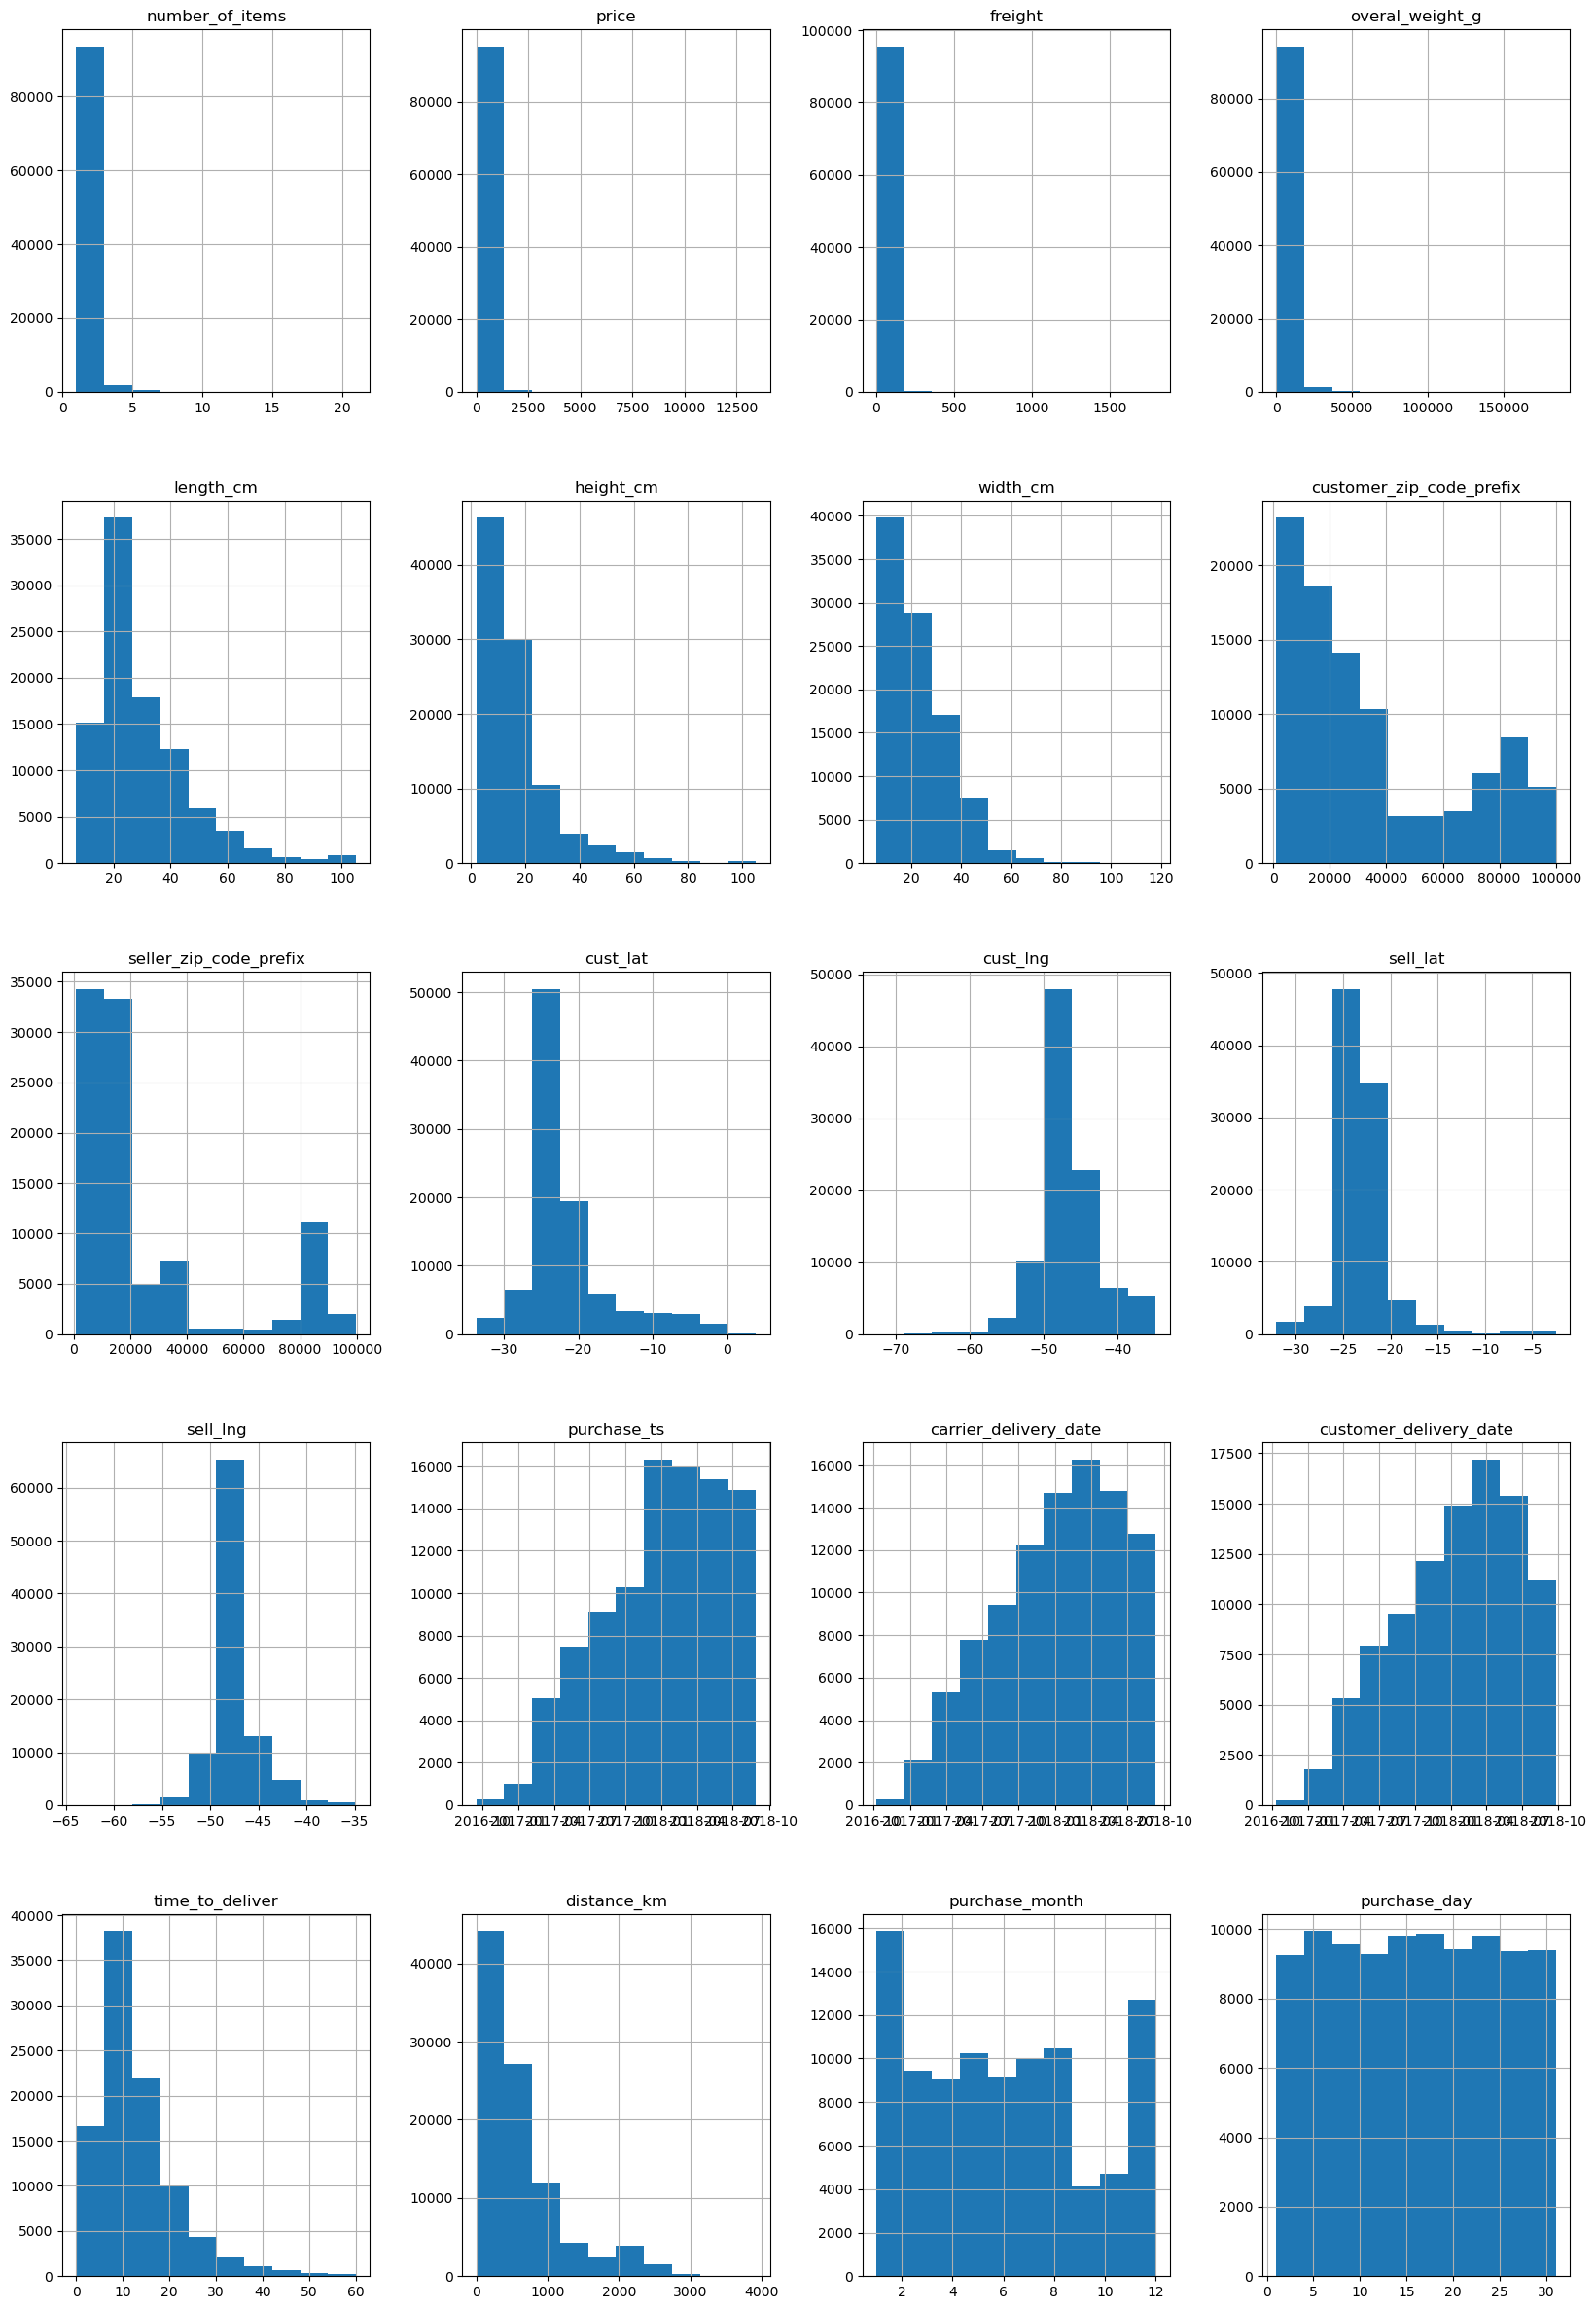

In [63]:
order_df.hist(figsize=(20,30));

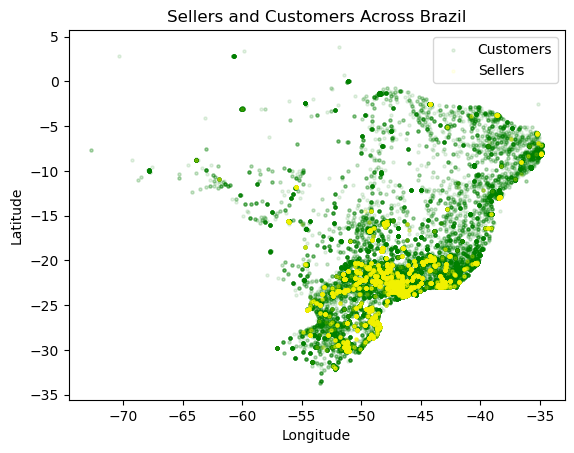

In [188]:
plt.scatter(order_df["cust_lng"], order_df["cust_lat"], s=5, alpha=0.1, color="green", label="Customers")
plt.scatter(order_df["sell_lng"], order_df["sell_lat"], s=5, alpha=0.07, color="yellow", label="Sellers")
plt.legend()

plt.title("Sellers and Customers Across Brazil")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

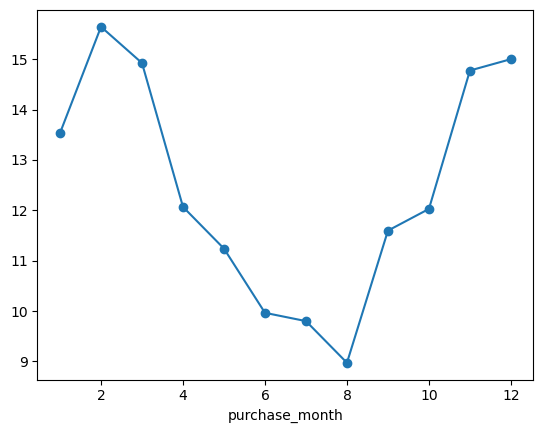

In [190]:
month_avg = order_df.groupby('purchase_month')['time_to_deliver'].mean()

month_avg.plot(kind='line', marker='o'); 

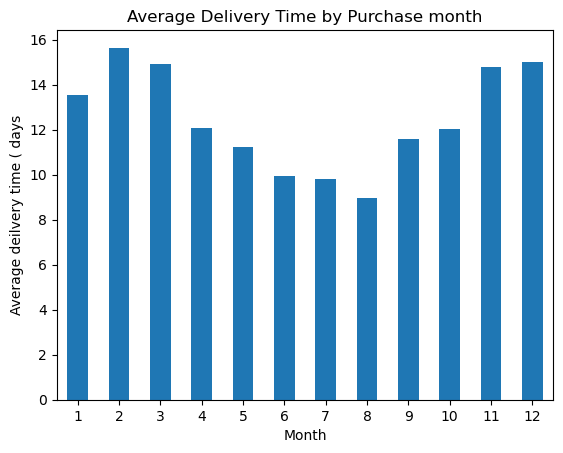

In [69]:
order_df.groupby("purchase_month")["time_to_deliver"].mean().plot(kind="bar");
plt.xticks(rotation=0)
plt.title("Average Delivery Time by Purchase month")
plt.xlabel("Month")
plt.ylabel("Average deilvery time ( days")
plt.show()

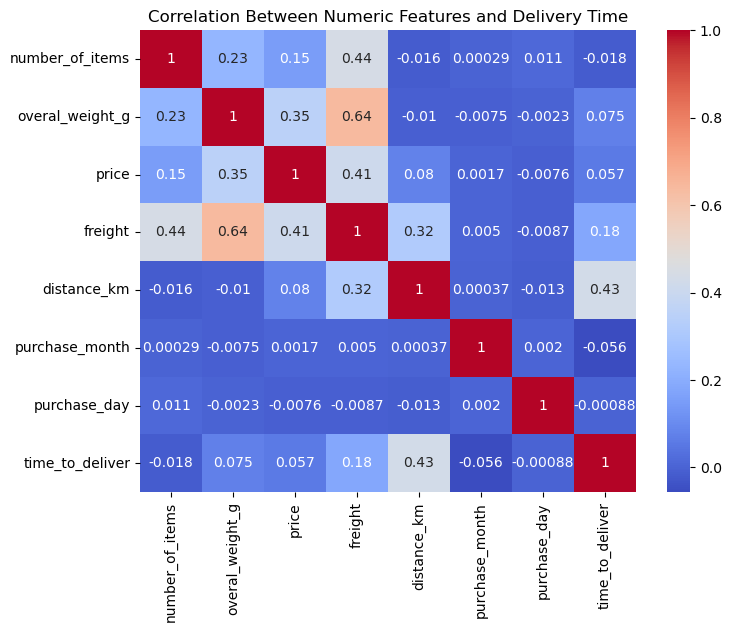

In [71]:
num_cols = ['number_of_items', 'overal_weight_g','price' ,'freight', 'distance_km',
             'purchase_month', 'purchase_day']

corr_cols = num_cols + ['time_to_deliver']
plt.figure(figsize=(8, 6))
sns.heatmap(order_df[corr_cols].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Numeric Features and Delivery Time')
plt.show()

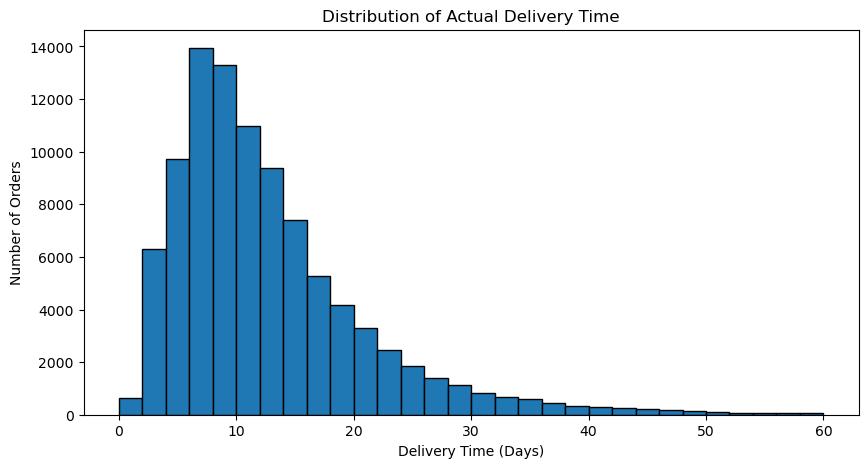

count    95670.000000
mean        12.255336
std          8.387728
min          0.000000
25%          7.000000
50%         10.000000
75%         16.000000
max         60.000000
Name: time_to_deliver, dtype: float64


In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(order_df["time_to_deliver"], bins=30, edgecolor="black")

plt.title("Distribution of Actual Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.show()

print(order_df["time_to_deliver"].describe())

In [83]:
state_summary = order_df.groupby("customer_state")["time_to_deliver"].agg(
    ["count", "median", "std", "min", "max"]
)

state_summary = state_summary.sort_values(
    "std", ascending=False
)

print(state_summary)

                     count  median        std  min  max
customer_state                                         
Roraima                 38    24.0  12.054169    6   54
Para                   927    21.0  10.713831    5   60
Alagoas                393    22.0  10.502840    4   60
Amazonas               144    26.0  10.214880    4   57
Rio de Janeiro       12205    12.0   9.994577    0   60
Sergipe                331    18.0   9.940449    6   56
Rio Grande do Norte    467    16.0   9.856969    1   55
Ceara                 1250    18.0   9.721396    3   58
Pernambuco            1580    16.0   9.490042    2   57
Paraiba                506    18.0   9.430115    6   54
Maranhao               708    19.0   9.321959    3   58
Bahia                 3211    17.0   8.862871    1   60
Piaui                  469    16.0   8.826420    2   58
Rio Grande do Sul     5316    13.0   8.327487    1   60
Santa Catarina        3529    13.0   8.160069    2   59
Mato Grosso            878    16.0   7.941511   

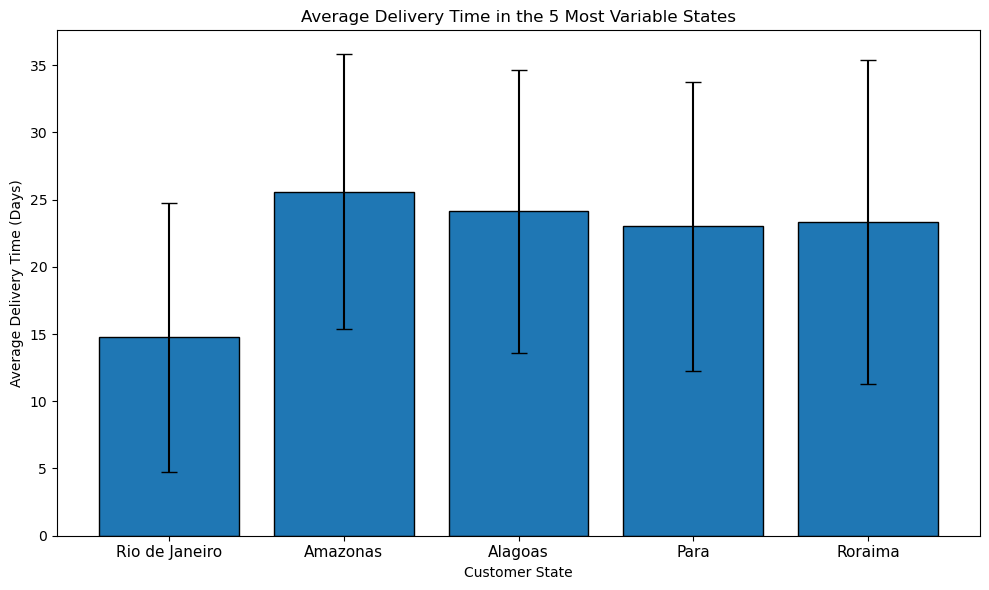

In [93]:
state_summary = order_df.groupby("customer_state")["time_to_deliver"].agg(mean="mean",variance="var",std="std")
#i will only selcet the top 5 in variation just for illistration
top_5 = state_summary.nlargest(5, "variance")

top_5 = top_5.sort_values("variance")

plt.figure(figsize=(10, 6))

plt.bar(top_5.index,top_5["mean"],yerr=top_5["std"],capsize=6,edgecolor="black")

plt.title("Average Delivery Time in the 5 Most Variable States")
plt.xlabel("Customer State")
plt.ylabel("Average Delivery Time (Days)")

plt.xticks(rotation=0, fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()

In [192]:
order_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 95670 entries, 0 to 96448
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   order_id                  95670 non-null  object        
 1   customer_id               95670 non-null  object        
 2   number_of_items           95670 non-null  int64         
 3   price                     95670 non-null  float64       
 4   freight                   95670 non-null  float64       
 5   overal_weight_g           95670 non-null  float64       
 6   length_cm                 95648 non-null  float64       
 7   height_cm                 95648 non-null  float64       
 8   width_cm                  95648 non-null  float64       
 9   product_id                95670 non-null  object        
 10  product_category_name     94342 non-null  object        
 11  seller_id                 95670 non-null  object        
 12  customer_state         

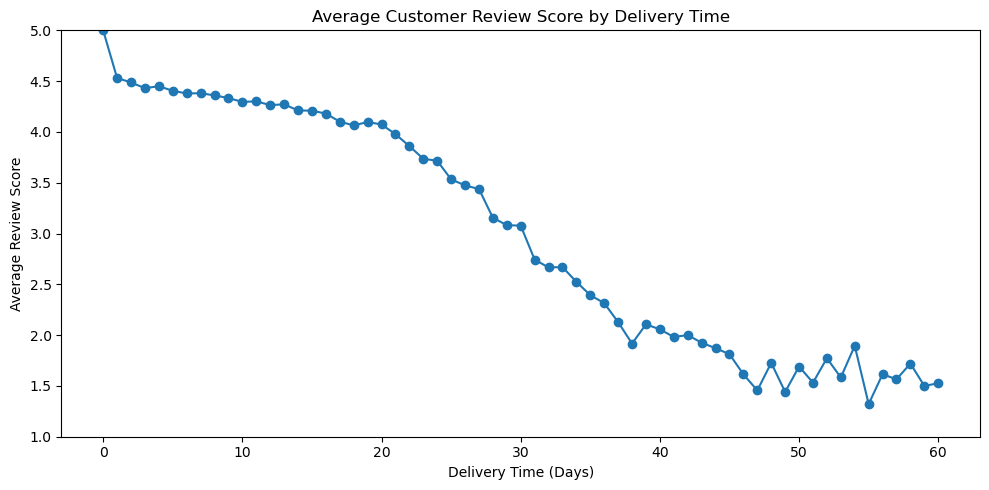

In [196]:
review_by_days = order_df.groupby("time_to_deliver")["review_score"].mean()

plt.figure(figsize=(10, 5))
plt.plot(review_by_days.index, review_by_days.values, marker="o")

plt.title("Average Customer Review Score by Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Average Review Score")
plt.ylim(1, 5)
plt.grid(False)
plt.tight_layout()
plt.show()

# Train, Val, Test

In [39]:
x = order_df.drop(columns='time_to_deliver')
y = order_df['time_to_deliver']

x_train_val, x_test, y_train_val, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_train_val, y_train_val, test_size=0.2, random_state=42)


# Pipeline

In [41]:
order_df.columns

Index(['order_id', 'customer_id', 'number_of_items', 'price', 'freight',
       'overal_weight_g', 'length_cm', 'height_cm', 'width_cm', 'product_id',
       'product_category_name', 'seller_id', 'customer_state', 'seller_state',
       'customer_zip_code_prefix', 'seller_zip_code_prefix', 'cust_lat',
       'cust_lng', 'sell_lat', 'sell_lng', 'purchase_ts',
       'carrier_delivery_date', 'customer_delivery_date', 'time_to_deliver',
       'distance_km', 'purchase_month', 'purchase_day'],
      dtype='object')

In [42]:
num_cols = ['number_of_items', 'overal_weight_g','price' ,'freight', 'distance_km',
             'purchase_month', 'purchase_day']
cat_cols = ['product_category_name', 'seller_state', 'customer_state']

In [43]:
x_train_num_pipe =  make_pipeline(SimpleImputer(), StandardScaler())
x_train_cat_pipe = make_pipeline(SimpleImputer(strategy='constant', fill_value='unkown'), OneHotEncoder(sparse_output=False, handle_unknown='ignore'))

In [44]:
preprocessing_pipe = ColumnTransformer([
    ('num', x_train_num_pipe, num_cols),
    ('cat', x_train_cat_pipe, cat_cols)
])
preprocessing_pipe

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

# Linear regression

In [68]:
regression_model = make_pipeline(preprocessing_pipe,LinearRegression() )
regression_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different

In [69]:
y_pred_reg_val=regression_model.predict(x_val)
mean_absolute_error(y_val, y_pred_reg_val)

5.1384321588270305

# KNN

In [45]:
full_pipe_knn = make_pipeline(preprocessing_pipe, KNeighborsRegressor(n_neighbors=7))

In [46]:
full_pipe_knn.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differ

In [47]:
y_pred_knn = full_pipe_knn.predict(x_train)
mean_absolute_error(y_train, y_pred_knn)

4.233977918599334

In [48]:
y_pred_val_knn = full_pipe_knn.predict(x_val)
mean_absolute_error(y_val, y_pred_val_knn)

4.954412258762925

### Random search 

In [52]:
param_rand_grid = {
    'kneighborsregressor__n_neighbors': [10, 15, 20, 30],
    'kneighborsregressor__weights': ['uniform', 'distance']

}

random_grid_model = RandomizedSearchCV(full_pipe_knn, param_rand_grid, n_iter=8,
                                       scoring='neg_mean_absolute_error', random_state=42)
random_grid_model.fit(x_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...eighbors=7))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'kneighborsregressor__n_neighbors': [10, 15, ...], 'kneighborsregressor__weights': ['uniform', 'distance']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... ver

In [53]:
random_grid_model.best_params_

{'kneighborsregressor__weights': 'distance',
 'kneighborsregressor__n_neighbors': 30}

In [54]:
y_pred_val_rand = random_grid_model.predict(x_val)
mean_absolute_error(y_val, y_pred_val_rand)

4.751978468710743

# Booster

## Hist Booster

In [55]:
hgb_pipe = make_pipeline(preprocessing_pipe, HistGradientBoostingRegressor(learning_rate= 0.12, min_samples_leaf=5 , max_iter=450, random_state=42))
hgb_pipe.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('histgradientboostingregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

In [56]:
y_pred_hgb = hgb_pipe.predict(x_val)
mean_absolute_error(y_val, y_pred_hgb)

4.597545282514427

## XGB model

In [63]:
xgboost_model = make_pipeline(preprocessing_pipe,XGBRegressor(random_state=42) )
xgboost_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('xgbregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

In [65]:
y_pred_val=xgboost_model.predict(x_val)

mae_lr = mean_absolute_error(y_val, y_pred_val)
rmse_lr = np.sqrt(mean_squared_error(y_val, y_pred_val))
r2_lr = r2_score(y_val, y_pred_val)

print(f"XGB MAE: {mae_lr:.2f}")
print(f"XGB RMSE: {rmse_lr:.2f}")
print(f"XGB R2: {r2_lr:.2f}")

XGB MAE: 4.56
XGB RMSE: 6.67
XGB R2: 0.39


# Decision Tree

In [70]:
full_pipe_dt = make_pipeline(preprocessing_pipe, DecisionTreeRegressor(random_state=42))
full_pipe_dt.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the diff

In [71]:
y_pred_val_dt = full_pipe_dt.predict(x_val)
mean_absolute_error(y_val, y_pred_val_dt)

6.232754115495166

## random search

In [75]:
param_dt = {
    'decisiontreeregressor__max_depth': [5, 8, 10, 15],
    'decisiontreeregressor__min_samples_leaf': [10, 20, 25, 30],
    'decisiontreeregressor__min_samples_split': [10, 15, 20, 25],
}

dt_search = RandomizedSearchCV(full_pipe_dt, param_dt, n_iter=10,
                               scoring='neg_mean_absolute_error',
                               random_state=42)
dt_search.fit(x_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'decisiontreeregressor__max_depth': [5, 8, ...], 'decisiontreeregressor__min_samples_leaf': [10, 20, ...], 'decisiontreeregressor__min_samples_split': [10, 15, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the vari

In [76]:
dt_search.best_params_

{'decisiontreeregressor__min_samples_split': 10,
 'decisiontreeregressor__min_samples_leaf': 30,
 'decisiontreeregressor__max_depth': 10}

In [77]:
y_pred_val_rand_dt = dt_search.predict(x_val)
mean_absolute_error(y_val, y_pred_val_rand_dt)

4.770678744225816

# Random Forest

In [72]:
full_pipe_rf = make_pipeline(preprocessing_pipe,
                             RandomForestRegressor(random_state=42, n_jobs=-1))
full_pipe_rf.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the diff

In [73]:
y_pred_val_rf = full_pipe_rf.predict(x_val)
mean_absolute_error(y_val, y_pred_val_rf)

4.608398818337544

# Model Comparison

In [78]:
mae_lr = mean_absolute_error(y_val, regression_model.predict(x_val))
mae_knn = mean_absolute_error(y_val, full_pipe_knn.predict(x_val))
mae_knn_tuned = mean_absolute_error(y_val, random_grid_model.predict(x_val))
mae_hgb = mean_absolute_error(y_val, hgb_pipe.predict(x_val))
mae_xgb = mean_absolute_error(y_val, xgboost_model.predict(x_val))
mae_dt = mean_absolute_error(y_val, full_pipe_dt.predict(x_val))
mae_dt_tuned = mean_absolute_error(y_val, dt_search.predict(x_val))
mae_rf = mean_absolute_error(y_val, full_pipe_rf.predict(x_val))

mae_df = pd.DataFrame({
    'model': ['Linear Regression', 'KNN', 'KNN tuned', 'Hist Booster',
              'XGBoost', 'Decision Tree', 'Decision Tree tuned', 'Random Forest'],
    'val_mae': [mae_lr, mae_knn, mae_knn_tuned, mae_hgb,
                mae_xgb, mae_dt, mae_dt_tuned, mae_rf]
})

mae_df = mae_df.sort_values('val_mae')
mae_df

,model,val_mae
4,XGBoost,4.557970
3,Hist Booster,4.597545
7,Random Forest,4.608399
2,KNN tuned,4.751978
6,Decision Tree tuned,4.770679
1,KNN,4.954412
0,Linear Regression,5.138432
5,Decision Tree,6.232754


# Model comaprison - Test

In [ ]:
mae_lr = mean_absolute_error(y_test, regression_model.predict(x_test))
mae_knn = mean_absolute_error(y_test, full_pipe_knn.predict(x_test))
mae_knn_tuned = mean_absolute_error(y_test, random_grid_model.predict(x_test))
mae_hgb = mean_absolute_error(y_test, hgb_pipe.predict(x_test))
mae_xgb = mean_absolute_error(y_test, xgboost_model.predict(x_test))
mae_dt = mean_absolute_error(y_test, full_pipe_dt.predict(x_test))
mae_dt_tuned = mean_absolute_error(y_test, dt_search.predict(x_test))
mae_rf = mean_absolute_error(y_test, full_pipe_rf.predict(x_test))

In [ ]:
mae_stk = mean_absolute_error(y_test, stk_reg.predict(x_test))

all_df = pd.DataFrame({
    'model': ['Linear Regression (baseline)', 'KNN', 'KNN (tuned)', 'Decision Tree',
              'Decision Tree (tuned)', 'Hist Gradient Boosting', 'XGBoost',
              'Random Forest', 'Stacked model (final)'],
    'mae': [mae_lr, mae_knn, mae_knn_tuned, mae_dt, mae_dt_tuned,
            mae_hgb, mae_xgb, mae_rf, mae_stk]
})

all_df = all_df.sort_values('mae', ascending=False)
all_df

In [ ]:
plt.figure(figsize=(10, 6))
bars = plt.barh(all_df['model'], all_df['mae'])
plt.bar_label(bars, fmt='%.2f', fontsize=12)
plt.xlabel('Average error (days) - lower is better', fontsize=13)
plt.ylabel('Model', fontsize=13)
plt.title('Prediction Error Across All Models', fontsize=15)

plt.savefig('all_models_comparison2.png', dpi=200, bbox_inches='tight', transparent=True)
plt.show()

# Stack

In [113]:
estimators = [
    ('XGBoost', xgboost_model),
    ('rand_forest', full_pipe_rf),
    ('Rknn', random_grid_model.best_estimator_)
]
stk_reg = StackingRegressor(estimators, final_estimator=LinearRegression())

In [114]:
stk_reg.fit(x_train, y_train) 

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.","[('XGBoost', ...), ('rand_forest', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA regressor which will be used to combine the base estimators.The default regressor is a :class:`~sklearn.linear_model.RidgeCV`.",LinearRegression()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary ` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [115]:
y_val_stk = stk_reg.predict(x_val)
mean_absolute_error(y_val, y_val_stk)

4.4835281577760115

# Streamlit Deployment Configurations

In [116]:
joblib.dump(stk_reg, "model1.pk", compress=3)

['model.pkl']

In [100]:
states = order_df.groupby('customer_state')[['cust_lat', 'cust_lng']].mean()
states.to_csv("states.csv")

In [101]:
single = order_df[order_df['number_of_items'] == 1]

In [109]:
catalog = single.groupby(['product_category_name', 'seller_id'], as_index=False).agg(
    orders=('order_id', 'count'),
    price=('price', 'median'),
    freight=('freight', 'median'),
    overal_weight_g=('overal_weight_g', 'median'),
    seller_state=('seller_state', 'first'),
    sell_lat=('sell_lat', 'first'),
    sell_lng=('sell_lng', 'first')
)
catalog = catalog[catalog['orders'] >= 3]

In [110]:
catalog = catalog.merge(category_trans_df, on='product_category_name', how='left')
catalog['category_english'] = catalog['product_category_name_english'].fillna(catalog['product_category_name'])
catalog['category_english'] = catalog['category_english'].str.replace('_', ' ').str.title()
catalog.to_csv("catalog.csv", index=False)

In [111]:
print(order_df['product_category_name'].nunique())
print(catalog['product_category_name'].nunique())

73
71


In [108]:
geo_raw = pd.read_csv('Data_Cleaning/olist_geolocation_cols_cleaned.csv')
geo_raw.columns

Index(['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng',
       'geolocation_city', 'geolocation_state', 'state_name'],
      dtype='object')

In [112]:
geo_city = geo_raw.drop_duplicates('geolocation_zip_code_prefix')
geo_city = geo_city[['geolocation_zip_code_prefix', 'geolocation_city']]

order_city = order_df.merge(geo_city, left_on='customer_zip_code_prefix',
                            right_on='geolocation_zip_code_prefix', how='left')

cities = order_city.groupby(['customer_state', 'geolocation_city'], as_index=False).agg(
    orders=('order_id', 'count'),
    cust_lat=('cust_lat', 'mean'),
    cust_lng=('cust_lng', 'mean')
)
cities = cities[cities['orders'] >= 20]
cities = cities.rename(columns={'geolocation_city': 'city'})
cities.to_csv("cities.csv", index=False)

# Comparison with the Previous Estimate

In [125]:
raw_orders = pd.read_csv('Data_Cleaning/olist_orders_dataset.csv')
est_df = raw_orders[['order_id', 'order_estimated_delivery_date']].copy()
est_df['order_estimated_delivery_date'] = pd.to_datetime(est_df['order_estimated_delivery_date'])

In [126]:
test_df = x_test.copy()
test_df['actual'] = y_test
test_df['our_pred'] = stk_reg.predict(x_test)

In [132]:
test_df = test_df.merge(est_df, on='order_id', how='left')
test_df['olist_pred'] = (test_df['order_estimated_delivery_date'] - test_df['purchase_ts']).dt.days

test_df['olist_diff'] = test_df['olist_pred'] - test_df['actual']
test_df['our_diff'] = test_df['our_pred'] - test_df['actual']

In [134]:
print("Previous estimate, mean difference:", test_df['olist_diff'].mean())
print("Our model, mean difference:", test_df['our_diff'].mean())

print("Previous estimate, mean absolute difference:", test_df['olist_diff'].abs().mean())
print("Our model, mean absolute difference:", test_df['our_diff'].abs().mean())

Previous estimate, mean difference: 12.06673983484896
Our model, mean difference: 0.03982267143807632
Previous estimate, mean absolute difference: 13.164471621197867
Our model, mean absolute difference: 4.461631980325231


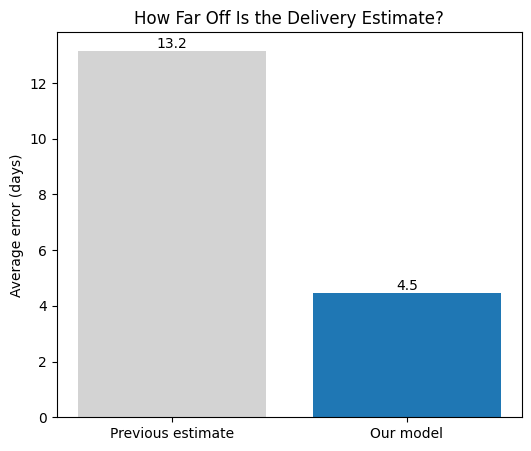

In [137]:
abs_olist = test_df['olist_diff'].abs().mean()
abs_ours = test_df['our_diff'].abs().mean()

plt.figure(figsize=(6, 5))
bars = plt.bar(['Previous estimate', 'Our model'], [abs_olist, abs_ours],
               color=['lightgrey', 'tab:blue'])
plt.bar_label(bars, fmt='%.1f')
plt.ylabel('Average error (days)')
plt.title('How Far Off Is the Delivery Estimate?')
plt.show()